# Gráficas interactivas de series de Fourier

In [1]:
# Librerías
%matplotlib inline   
from matplotlib import pyplot as plt
import numpy as np
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

ModuleNotFoundError: No module named 'ipywidgets'

## Grafica de serie trigonométrica de voltaje triangular y corriente

#### $v(t) = \displaystyle \frac{1}{2} -\sum_{n=1}^N \frac{4}{\pi^2 n^2}\cos(5,000nt)\;\;$  e  $\;\;i(t) = \displaystyle \frac{1}{8} -\sum_{n=1}^N \frac{4}{\pi^2n^2\sqrt{16+25n^2}}\cos \left(5,000nt - \arctan \left(\frac{5n}{4}\right)\right)$

In [ ]:
def Serie_Fourier(N):
    sfv = 0; sfi = 0
    for n in range (1, N, 2): # n 1, 3, 5, 7, ...
        def v(t):
            return -(4/np.pi**2)*np.cos(n*5000*t)/n**2 # Voltaje, T0 = 2pi/5000
        def i(t):
            return -(4/(np.pi*n)**2)/(np.sqrt(16+25*n**2))*np.cos(5000*n*t - np.arctan(5*n/4)) # Corriente
        t = np.linspace(-4*np.pi/5000, 4*np.pi/5000, 1000)
        sfv += v(t)
        sfi += i(t)
    v = 0.5 + sfv
    i = 1.0/8 + sfi
    #grid(True)
    plt.plot(t, v, 'k')
    #hold ('on')
    plt.plot(t, i, 'r')  

In [ ]:
interact(Serie_Fourier, N = (0, 10))

interactive(children=(IntSlider(value=5, description='N', max=10), Output()), _dom_classes=('widget-interact',…

<function __main__.Serie_Fourier(N)>

##### En la figura anterior, voltaje triangular en negro y corriente en rojo

## Gráfica de la serie trigonómetrica de diente de sierra

### $x(t) = t \;\; {\rm si} \;\; 0 \leq t \leq 2\pi \;\; T = 2\pi,\;\;\; \;x(t) =\pi -2\displaystyle \sum_{n=1}^N \frac{\sin(nt)}{n}$  

In [ ]:
def Series_Fourier_Sawtooth(N):
    sfs = 0;
    for n in range (1, N, 1): #n = 1, 2, 3, ...
        def s(t):
            return -2*np.sin(n*t)/n
        t = np.linspace(-2*np.pi, 4*np.pi, 1000)
        sfs += s(t)
    s = np.pi + sfs
    #grid(True)
    plt.plot(t, s, 'k')

In [ ]:
interact(Series_Fourier_Sawtooth, N = (1, 10))

interactive(children=(IntSlider(value=5, description='N', max=10, min=1), Output()), _dom_classes=('widget-int…

<function __main__.Series_Fourier_Sawtooth(N)>

## Gráfica de serie de onda triangular par

### $x(t)= \displaystyle \left\{  { -t, \hspace{2mm} -\pi\leq t\leq 0 \atop t, \hspace{9mm} 0 <  t < \pi } \right. \;\;\; T = 2\pi\;\;\;\; \;\;x(t) = \displaystyle \frac{\pi}{2} -\frac{4}{\pi} \sum_{n=1}^N \frac{\cos(nt)}{n^2}$

In [ ]:
def Series_Fourier_Triangle(N):
    sfs = 0;
    for n in range (1, N, 2):
        def s(t):
            return -4*np.cos(n*t)/(np.pi*n**2)  # T0 = 2pi
        t = np.linspace(-2*np.pi, 4*np.pi, 1000)
        sfs += s(t)
    s = np.pi/2 + sfs
    plt.plot(t, s, 'k')

In [ ]:
interact(Series_Fourier_Triangle, N = (1, 10))

interactive(children=(IntSlider(value=5, description='N', max=10, min=1), Output()), _dom_classes=('widget-int…

<function __main__.Series_Fourier_Triangle(N)>

## Gráficas del tren de pulsos rectangulares de voltaje y corriente en circuito RL, obtenidas con serie trigonométrica y análisis ac de circuitos (Resuelto en clase).

### $v(t) = \displaystyle 1+\frac{4}{\pi}\sum_{n=1}^N \frac{\sin(nt)}{n} \;\;\; i(t) = 1+\frac{4}{\pi} \sum_{n=1}^N \frac{\cos(nt)}{n^2+1} + \frac{\sin(nt)}{ n(n^2 +1)}\;\;\; it) = 1+ \frac{4}{\pi} \sum_{n=1}^N \frac{\sin(nt -\arctan(n))}{n\sqrt{1 + n^2}}$

In [ ]:
def Serie_Fourier_Pulso(N):
    sfv = 0; sfi = 0; sfc = 0
    for n in range (1, N, 2):
        def v(t):
            return 4*np.sin(n*t)/(np.pi*n) # Seire de volatje
        def i(t):
            return -4*np.cos(n*t)/(np.pi*(n**2 +1))+4*np.sin(n*t)/(np.pi*n*(n**2+1)) # Corriente con serie trig
        def c(t):
            return 4*np.sin(n*t - np.arctan(n))/(np.pi*n*np.sqrt(1 + n**2)) # Corriente con análisis de ac
        t = np.linspace(0, 10, 1000)
        sfv += v(t)
        sfi += i(t)
        sfc += c(t)
    v = 1 + sfv
    i = 1 + sfi
    c = 1 + sfc
    #grid(True)
    plt.plot(t, v, 'k')
    plt.plot(t, i, 'r') 
    plt.plot(t, c, 'b')
#  NOTA: En las copias puse 2*pi debe ser 4*pi,todos los coeficientes deben multiplicarse por 2

In [ ]:
interact(Serie_Fourier_Pulso, N = (1, 16))

interactive(children=(IntSlider(value=8, description='N', max=16, min=1), Output()), _dom_classes=('widget-int…

<function __main__.Serie_Fourier_Pulso(N)>

#### En la figura anterior la grafica de corriente obtenida usando la serie trigonométrica coincide con la gráfica de la corriente obtenida con análisis de corriente alterna de circuitos. La primera es roja y la segunda azul.

## Grafica de la serie compleja de la corriente del circuito RL resuelto en clase

C:\Users\USUARIO\anaconda3\lib\site-packages\matplotlib\cbook\__init__.py:1298: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


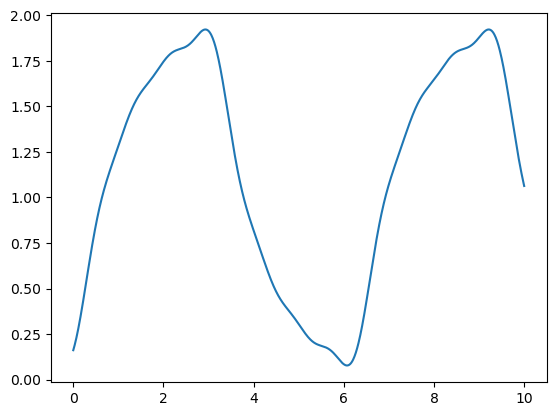

In [ ]:
t = np.linspace(0, 10, 1000)
plt.plot(t, 1 + 2*(1j/(np.pi*(1 - 1j))*np.exp(-1j*t) - 1j/(np.pi*(1 + 1j))*np.exp(1j*t)
                   + 1j/(np.pi*3*(1 - 1j*3))*np.exp(-1j*3*t) - 1j/(np.pi*3*(1 + 1j*3))*np.exp(1j*3*t)
                   + 1j/(np.pi*5*(1 - 1j*5))*np.exp(-1j*5*t) - 1j/(np.pi*5*(1 + 1j*5))*np.exp(1j*5*t) 
                   + 1j/(np.pi*7*(1 - 1j*7))*np.exp(-1j*7*t) - 1j/(np.pi*7*(1 + 1j*7))*np.exp(1j*7*t)))
#NOTA: En las copias puse Cn = -j/(pi*n), debe ser Cn = -2j/(pi*n), todos los coefs deben multiplicarse por 2.

#### En el circuito

###### 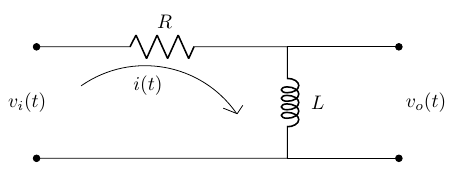

In [ ]:
def Series_Compleja(N):
    sfc = 0;
    for n in range (1, N, 2): #n = 1, 2, 3, ...
        def s(t):
            return 10*np.exp(1j*(n*t + np.arctan(1/n) - np.pi/2))/((n*np.pi)*np.sqrt(1 + 1/n**2)) +\
        10*np.exp(-1j*(n*t + np.arctan(1/n) - np.pi/2))/((n*np.pi)*np.sqrt(1 + 1/n**2))        
        t = np.linspace(-2*np.pi, 4*np.pi, 1000)
        sfc += s(t)
    s = sfc
    #grid(True)
    plt.plot(t, s, 'k')

In [ ]:
interact(Series_Compleja, N = (1, 16))

interactive(children=(IntSlider(value=8, description='N', max=16, min=1), Output()), _dom_classes=('widget-int…

<function __main__.Series_Compleja(N)>

C:\Users\USUARIO\anaconda3\lib\site-packages\numpy\core\_asarray.py:102: ComplexWarning: Casting complex values to real discards the imaginary part
  return array(a, dtype, copy=False, order=order)


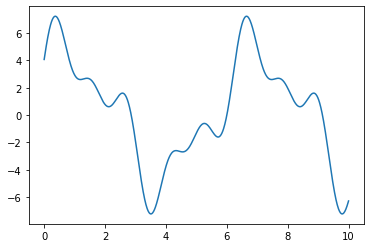

In [ ]:
t = np.linspace(0, 10, 1000)
plt.plot(t, 10*np.exp(1j*(1*t + np.arctan(1/1) - np.pi/2))/((1*np.pi)*np.sqrt(1 + 1/1**2)) +\
            10*np.exp(-1j*(1*t + np.arctan(1/1) - np.pi/2))/((1*np.pi)*np.sqrt(1 + 1/1**2)) +\
            10*np.exp(1j*(3*t + np.arctan(1/3) - np.pi/2))/((3*np.pi)*np.sqrt(1 + 1/3**2)) +\
            10*np.exp(-1j*(3*t + np.arctan(1/3) - np.pi/2))/((3*np.pi)*np.sqrt(1 + 1/3**2)) +\
            10*np.exp(1j*(5*t + np.arctan(1/5) - np.pi/2))/((5*np.pi)*np.sqrt(1 + 1/5**2)) +\
            10*np.exp(-1j*(5*t + np.arctan(1/5) - np.pi/2))/((5*np.pi)*np.sqrt(1 + 1/5**2)))

In [ ]:
20/((1*np.pi)*np.sqrt(1 + 1/1**2)) 

4.501581580785531